# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Delos Santos, Mico
- _Student No._: 2024-35117
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import math

from scipy.integrate import quad
import scipy.special as special

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



I_scipy_f1 = 3.534291735288518
error_f1 = 5.742084585591556e-11
I_scipy_f2 = -1.3333333333333335
error_f2 = 4.465845366792915e-14
I_scipy_f3 = -0.8948314694841447
error_f3 = 5.742084585591556e-11
3.5342498374451385
-1.3333440213653758
-0.8948683627997766
3.5342243029391165
-1.3293400173613719
-0.8929882840684703
3.5342325866032858
-1.330341336
-0.8934571396825032


<function matplotlib.pyplot.show(close=None, block=None)>

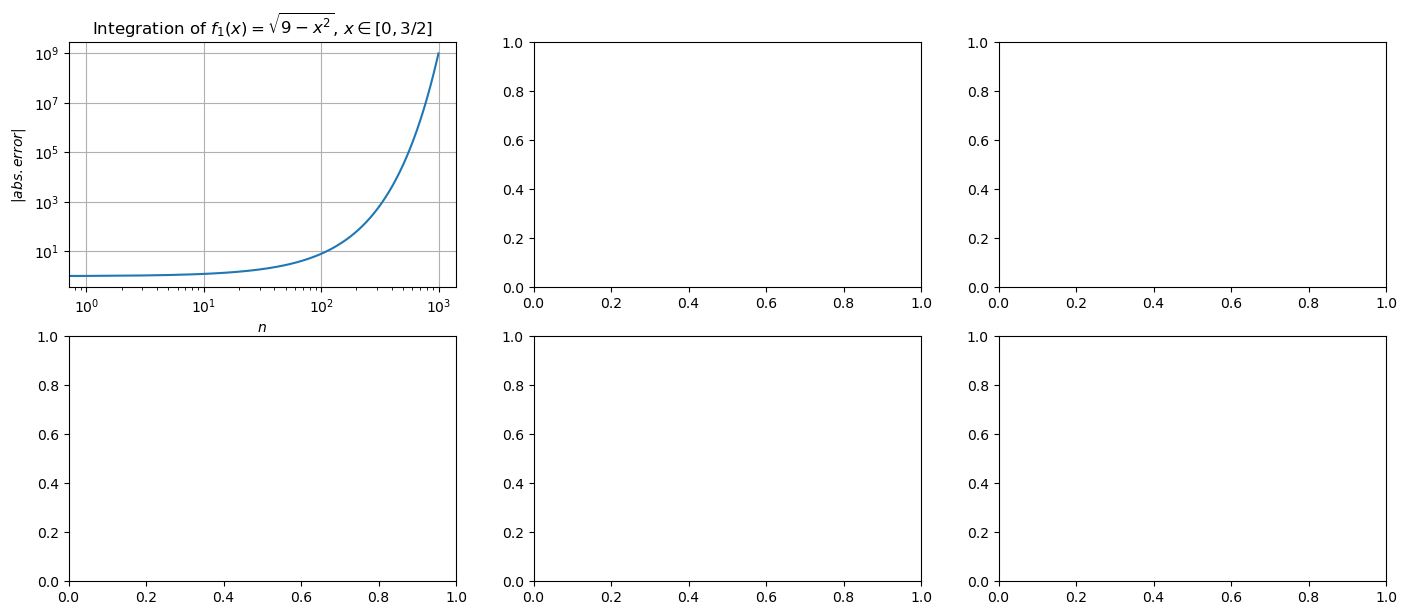

In [141]:
#functions given
def f1(x):
    return np.sqrt(9 - 4*x**2)
def f2(x):
    return -x**2 + 1
def f3(x):
    return np.sqrt(x)*np.cos(x)

#scipy,integrate.quad, quad = 1D int.
I_scipy_f1 = integrate.quad(f1, 0, 3/2)
print(f"I_scipy_f1 = {I_f1}")
print(f"error_f1 = {error}")

I_scipy_f2, error = integrate.quad(f2, -2, 2)
print(f"I_scipy_f2 = {I_f2}")
print(f"error_f2 = {error}")

I_scipy_f3, error = integrate.quad(f3, 0, np.pi)
print(f"I_scipy_f3 = {I_f3}")
print(f"error_f3 = {error}")

#trapezoidal integration
def trapezoidal(f,a,b,n):
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0] = 0.5; cs[-1] = 0.5
    contributions = cs*f(xs)
    return h*np.sum(contributions)

#simpson's rule 1/3 integration
def simpson13(f,a,b,n):
    h = (b - a)/(n - 1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    contributions = cs*f(xs)
    return (h/3)*np.sum(contributions)

#simpson's rule 3/8 integration
def simpson38(f,a,b,n):
    h = (b - a)/n
    xs = np.linspace(a, b, n + 1)
    y = f(xs)
    sum_mult_3 = np.sum(y[3:-1:3])
    sum_remain = np.sum(y[1:-1]) - sum_mult_3
    return (3*h/8)*(y[0] + 3*sum_remain + 2*sum_mult_3 + y[-1])
    
for integrator in (trapezoidal, simpson13, simpson38):
    print(integrator(f1, 0, 3/2, 1000))
    print(integrator(f2, -2, 2, 1000))
    print(integrator(f3, 0, np.pi, 1000))

ns = np.logspace(0, 9, 1000)
error_f1 = np.abs((integrator(f1, 0, 3/2, 1000) - integrate.quad(f1, 0, 3/2))/(integrate.quad(f1, 0, 3/2)))

fig, axs = plt.subplots(2, 3, figsize=(17,7))
axs[0, 0].loglog(ns, )
axs[0, 0].set_title(r"Integration of $f_1(x) = \sqrt{9-x^2}$, $x\in[0, 3/2]$")
axs[0, 0].set_xlabel("$n$")
axs[0, 0].set_ylabel(r"$\vert abs.error \vert$")
axs[0, 0].grid(True)
plt.show